# Predicción de biodegradabilidad de sustancias químicas

**Proyecto integrador**
Machine Learning e Inferencia Bayesiana

El proyecto estudia la clasificación de sustancias químicas según su biodegradabilidad mediante
cinco algoritmos de aprendizaje supervisado. El análisis relaciona descriptores moleculares con
etiquetas experimentales y compara el desempeño de los clasificadores mediante métricas de evaluación.


## 1. Introducción

La biodegradabilidad es la capacidad de una sustancia para transformarse por la actividad de
microorganismos. Su estudio ayuda a comprender qué puede ocurrir con los compuestos que llegan
al ambiente. La clasificación depende de las condiciones y criterios de los ensayos: no es una
garantía universal de cómo se comportará una sustancia en cualquier ecosistema.

El análisis se basó en descriptores moleculares ya calculados para estudiar la relación
entre las características de las moléculas y su etiqueta experimental. El aprendizaje automático
puede apoyar el análisis y la comparación de sustancias; los resultados no sustituyen ensayos
experimentales ni una evaluación ambiental.

**Pregunta de investigación:** ¿cuál de cinco modelos clásicos de Machine Learning clasifica
mejor la biodegradabilidad de sustancias químicas a partir de sus descriptores moleculares?
Se estableció como criterio de comparación el mayor F1 de RB en validación cruzada de entrenamiento.

## 2. Objetivos

**Objetivo general:** comparar cinco algoritmos clásicos de clasificación supervisada para
predecir si una sustancia es fácilmente biodegradable a partir de sus características moleculares.

**Objetivos específicos:**

1. Verificar la estructura, calidad y significado de las variables del archivo original.
2. Preparar los datos y explorar sus distribuciones y asociaciones con gráficos sencillos.
3. Entrenar Regresión Logística, KNN, SVM, Gaussian Naive Bayes y Random Forest en los mismos datos.
4. Comparar los modelos mediante validación cruzada estratificada y evaluar sus predicciones finales.
5. Seleccionar un modelo justificando su rendimiento, sus limitaciones y sus fundamentos matemáticos.

## 3. Descripción del dataset

La fuente es [QSAR biodegradation](https://archive.ics.uci.edu/dataset/254/qsar+biodegradation), obtenida en UCI Machine Learning Repository.
La documentación describe **1,055 observaciones, 41 predictores y una clase**.
Se verificó estas cantidades permitiendo determinar el tamaño de la muestra tras la limpieza.
Las columnas no identifican las sustancias por nombre: son medidas numéricas enteras o reales
de composición, grupos funcionales y estructura molecular. Ejemplificados en la siguiente tabla:

| Descriptor | Interpretación sencilla |
|---|---|
| `nO` | Número de átomos de oxígeno |
| `nN` | Número de átomos de nitrógeno |
| `nX` | Número de átomos de halógenos |
| `C%` | Porcentaje de átomos de carbono; no es porcentaje en masa |
| `nHDon` | Número de átomos donadores de enlaces de hidrógeno (N y O) |

El resto incluye conteos de fragmentos y combinaciones matemáticas de la estructura molecular.
Los valores ya están incluidos en el archivo y se emplearon directamente como entradas de los clasificadores.
La lista de nombres de los descriptores moleculares y de la clase experimental se encuentran en la sección **Additional Variable Information** en UCI.

La etiqueta **RB** indica fácilmente biodegradable (*Ready Biodegradable*);
**NRB**, no clasificada como fácilmente biodegradable (*Not Ready Biodegradable*).
NRB no significa que la sustancia jamás pueda biodegradarse.
Se trata de clasificación binaria supervisada porque cada observación tiene una etiqueta experimental
y el objetivo es asignar una de dos categorías, en lugar de predecir una cantidad continua con metodos de regresión.

## 4. Carga y revisión inicial

El archivo utiliza `;` como separador, en vez de comas `,` , y no contiene encabezados declarados. La revisión inicial comprobó sus dimensiones, los tipos de datos, las clases, los valores faltantes, los duplicados y las posibles etiquetas contradictorias. Los nombres oficiales se asignaron según el orden de UCI.

In [33]:
from pathlib import Path
from time import perf_counter
import hashlib
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    make_scorer, confusion_matrix, ConfusionMatrixDisplay,
)
from sklearn.utils.validation import check_is_fitted

SEMILLA = 42
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 11})
pd.set_option("display.max_columns", 12)


In [34]:
# Orden de los descriptores verificado en la lista numerada oficial de UCI.
descriptores = [
    "SpMax_L", "J_Dz(e)", "nHM", "F01[N-N]", "F04[C-N]",
    "NssssC", "nCb-", "C%", "nCp", "nO", "F03[C-N]", "SdssC",
    "HyWi_B(m)", "LOC", "SM6_L", "F03[C-O]", "Me", "Mi", "nN-N",
    "nArNO2", "nCRX3", "SpPosA_B(p)", "nCIR", "B01[C-Br]",
    "B03[C-Cl]", "N-073", "SpMax_A", "Psi_i_1d", "B04[C-Br]",
    "SdO", "TI2_L", "nCrt", "C-026", "F02[C-N]", "nHDon",
    "SpMax_B(m)", "Psi_i_A", "nN", "SM6_B(m)", "nArCOOR", "nX",
]
assert len(descriptores) == 41 and len(set(descriptores)) == 41

ruta_csv = Path("data") / "raw" / "biodeg.csv"
if not ruta_csv.is_file():
    raise FileNotFoundError("Abra el notebook desde la raíz: falta data/raw/biodeg.csv.")
huella_original = hashlib.sha256(ruta_csv.read_bytes()).hexdigest()
datos_originales = pd.read_csv(ruta_csv, sep=";", header=None)
if datos_originales.shape != (1055, 42):
    raise ValueError(f"Estructura inesperada: {datos_originales.shape}; revisar antes de continuar.")
datos_originales.columns = descriptores + ["clase"]
display(datos_originales.head())

,SpMax_L,J_Dz(e),nHM,F01[N-N],F04[C-N],NssssC,...,Psi_i_A,nN,SM6_B(m),nArCOOR,nX,clase
0,3.919,2.6909,0,0,0,0,...,1.591,0,7.253,0,0,RB
1,4.170,2.1144,0,0,0,0,...,1.967,0,7.257,0,0,RB
2,3.932,3.2512,0,0,0,0,...,2.417,0,7.601,0,0,RB
3,3.000,2.7098,0,0,0,0,...,5.000,0,6.690,0,0,RB
4,4.236,3.3944,0,0,0,0,...,2.405,0,8.003,0,0,RB


In [35]:
# Detección de valores no numéricos antes de cualquier imputación o escalado.
entradas_numericas = datos_originales[descriptores].apply(pd.to_numeric, errors="coerce")
no_numericos = (
    entradas_numericas.isna() & datos_originales[descriptores].notna()
).sum().sum()
faltantes = int(datos_originales.isna().sum().sum())
duplicados_exactos = int(datos_originales.duplicated().sum())

# Mismos 41 valores numéricos pero más de una etiqueta: conflicto que exige revisión.
revision = entradas_numericas.assign(clase=datos_originales["clase"])
clases_por_entrada = revision.groupby(descriptores, dropna=False)["clase"].nunique()
conflictos = clases_por_entrada[clases_por_entrada > 1]

display(pd.Series({
    "Registros": len(datos_originales), "Predictores": len(descriptores),
    "Columnas totales": datos_originales.shape[1], "Valores faltantes": faltantes,
    "Duplicados exactos redundantes": duplicados_exactos,
    "Valores no numéricos inesperados": int(no_numericos),
    "Entradas con etiquetas contradictorias": len(conflictos),
}, name="Auditoría").to_frame())

display(pd.DataFrame({
    "posición (1 a 42)": range(1, 43),
    "nombre": datos_originales.columns,
    "tipo leído": datos_originales.dtypes.astype(str).to_numpy(),
    "faltantes": datos_originales.isna().sum().to_numpy(),
}))
conteos_originales = datos_originales["clase"].value_counts().reindex(["NRB", "RB"])
display(pd.DataFrame({
    "registros": conteos_originales,
    "porcentaje": 100 * conteos_originales / len(datos_originales),
}).round(2))
print("Filas que participan en grupos de duplicados exactos:")
display(datos_originales.loc[datos_originales.duplicated(keep=False)])

if set(datos_originales["clase"].unique()) != {"RB", "NRB"}:
    raise ValueError("Etiquetas inesperadas: se requiere revisar el CSV.")
if len(conflictos):
    display(conflictos)
    raise ValueError("Hay entradas con etiquetas contradictorias. Consultar antes de tratarlas.")
if no_numericos or faltantes or not np.isfinite(entradas_numericas.to_numpy()).all():
    raise ValueError("Hay valores inválidos o faltantes: revisar el tratamiento antes de continuar.")

,Auditoría
Registros,1055
Predictores,41
Columnas totales,42
Valores faltantes,0
Duplicados exactos redundantes,3
Valores no numéricos inesperados,0
Entradas con etiquetas contradictorias,0


,posición (1 a 42),nombre,tipo leído,faltantes
0,1,SpMax_L,float64,0
1,2,J_Dz(e),float64,0
2,3,nHM,int64,0
3,4,F01[N-N],int64,0
4,5,F04[C-N],int64,0
5,6,NssssC,int64,0
6,7,nCb-,int64,0
7,8,C%,float64,0
8,9,nCp,int64,0
9,10,nO,int64,0


,registros,porcentaje
clase,,
NRB,699,66.26
RB,356,33.74


Filas que participan en grupos de duplicados exactos:


,SpMax_L,J_Dz(e),nHM,F01[N-N],F04[C-N],NssssC,...,Psi_i_A,nN,SM6_B(m),nArCOOR,nX,clase
132,4.343,3.9399,0,0,0,0,...,4.167,0,8.016,0,0,RB
178,4.983,4.2631,0,0,0,0,...,3.694,0,7.880,0,0,RB
196,4.343,3.9399,0,0,0,0,...,4.167,0,8.016,0,0,RB
268,4.983,4.2631,0,0,0,0,...,3.694,0,7.880,0,0,RB
299,5.998,1.8789,6,0,0,3,...,2.355,0,9.843,0,6,NRB
910,5.998,1.8789,6,0,0,3,...,2.355,0,9.843,0,6,NRB


## 5. Limpieza y preprocesamiento

Se eliminaron únicamente las repeticiones exactas de las 42 columnas, conservando una copia.
Son redundantes para este análisis por observación: el CSV no incluye identificadores que
permitan reconocerlas como ensayos independientes. Esta decisión evita que una copia idéntica
llegue a entrenamiento y otra a prueba. No implica que todos los compuestos químicamente
relacionados queden separados.

Las clases se codificaron como **RB = 1** y **NRB = 0**; esta numeración permite calcular métricas de RB como clase positiva y NRB como clase negativa.
Se conservaron los **41 predictores** y no se eliminaron valores extremos automáticamente.

El preprocesamiento se definió antes de evaluar los modelos:

| Modelos | Preprocesamiento | Motivo |
|---|---|---|
| Regresión Logística, KNN y SVM | `StandardScaler` dentro de cada `Pipeline` | Evitar que unidades y magnitudes dominen distancias o regularización |
| Gaussian Naive Bayes | Valores numéricos originales | Estima una media y una varianza por variable y clase; no requiere distancias comparables |
| Random Forest | Valores numéricos originales | Las divisiones de los árboles no necesitan estandarización |

La estandarización ajusta los valores de cada variable restando su media y dividiendo entre su desviación estándar. Este proceso se realiza únicamente con los datos de entrenamiento y se repite en cada partición de la validación cruzada, evitando utilizar información de los datos de validación o prueba.

Los valores extremos se revisaron durante el análisis exploratorio (EDA), sin eliminarlos automáticamente.

In [36]:
datos = datos_originales.drop_duplicates().copy()
datos[descriptores] = entradas_numericas.loc[datos.index]
X = datos[descriptores].copy()
y = datos["clase"].map({"NRB": 0, "RB": 1}).astype(int)

display(Markdown(
    f"Se retiraron **{len(datos_originales) - len(datos)} copias redundantes** y quedaron "
    f"**{len(datos)} observaciones únicas**, con **{X.shape[1]} predictores**. "
    f"Se encontraron **{faltantes} valores faltantes**: no fue necesario imputar. "
    "No se eliminaron valores extremos ni variables, y no se modificó el archivo original."
))
display(datos["clase"].value_counts().reindex(["NRB", "RB"]).rename("Registros limpios").to_frame())

Se retiraron **3 copias redundantes** y quedaron **1052 observaciones únicas**, con **41 predictores**. Se encontraron **0 valores faltantes**: no fue necesario imputar. No se eliminaron valores extremos ni variables, y no se modificó el archivo original.

,Registros limpios
clase,
NRB,698
RB,354


## 6. Análisis exploratorio de datos (EDA)

Antes del análisis exploratorio (EDA), los datos se dividieron en 80% para entrenamiento y 20% para prueba. Las gráficas se realizaron únicamente con los datos de entrenamiento. Se seleccionaron algunas variables para visualizar sus características, pero los cinco modelos utilizaron los 41 descriptores disponibles.

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA,
)
eda = X_train.copy()
eda["clase"] = y_train.map({0: "NRB", 1: "RB"})
variables_sencillas = ["nO", "nN", "C%"]

### Distribución de clases

Las alturas muestran cuántas observaciones hay por categoría en entrenamiento.
Una clase mayoritaria puede dar un accuracy aparentemente alto aunque se reconozcan pocas RB.
La tabla de la auditoría permite consultar también la distribución del archivo completo.

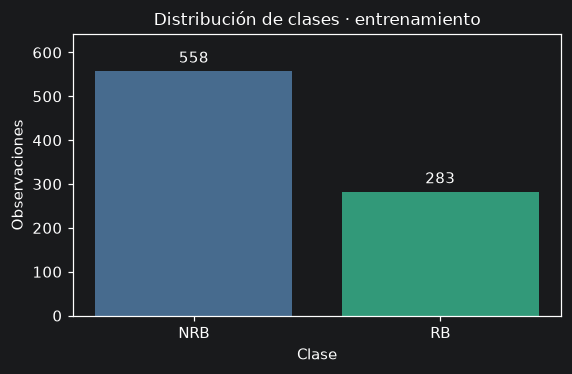

En entrenamiento, **NRB representa 66.3%** y **RB 33.7%**. Por ello se comparan precision, recall y F1 de RB, además de accuracy.

In [38]:
conteos_train = eda["clase"].value_counts().reindex(["NRB", "RB"])
fig, ax = plt.subplots(figsize=(5.3, 3.5))
barras = ax.bar(conteos_train.index, conteos_train.values, color=["#476b8e", "#329979"])
ax.bar_label(barras, padding=3)
ax.set(title="Distribución de clases · entrenamiento", xlabel="Clase", ylabel="Observaciones")
ax.set_ylim(0, conteos_train.max() * 1.15)
fig.tight_layout()
plt.show()
display(Markdown(
    f"En entrenamiento, **NRB representa {100 * (y_train == 0).mean():.1f}%** "
    f"y **RB {100 * y_train.mean():.1f}%**. Por ello se comparan precision, recall y F1 de RB, "
    "además de accuracy."
))

### Estadísticas descriptivas e histogramas

La tabla resume los 41 descriptores del entrenamiento mediante medidas de tendencia central,
dispersión y posición. Las escalas varían según el tipo de descriptor, como un conteo o un
porcentaje. Los histogramas permiten observar la concentración de los valores y las posibles
colas de las distribuciones.

,count,mean,std,min,25%,50%,75%,max
SpMax_L,841.0,4.775,0.540,2.000,4.481,4.828,5.115,6.316
J_Dz(e),841.0,3.065,0.807,0.804,2.518,3.044,3.436,9.178
nHM,841.0,0.703,1.434,0.000,0.000,0.000,1.000,10.000
F01[N-N],841.0,0.038,0.241,0.000,0.000,0.000,0.000,3.000
F04[C-N],841.0,0.966,2.368,0.000,0.000,0.000,1.000,36.000
NssssC,841.0,0.263,0.970,0.000,0.000,0.000,0.000,12.000
nCb-,841.0,1.636,2.232,0.000,0.000,1.000,3.000,18.000
C%,841.0,37.015,9.176,0.000,30.400,37.500,42.900,60.700
nCp,841.0,1.384,1.996,0.000,0.000,1.000,2.000,24.000
nO,841.0,1.795,1.794,0.000,0.000,2.000,3.000,12.000


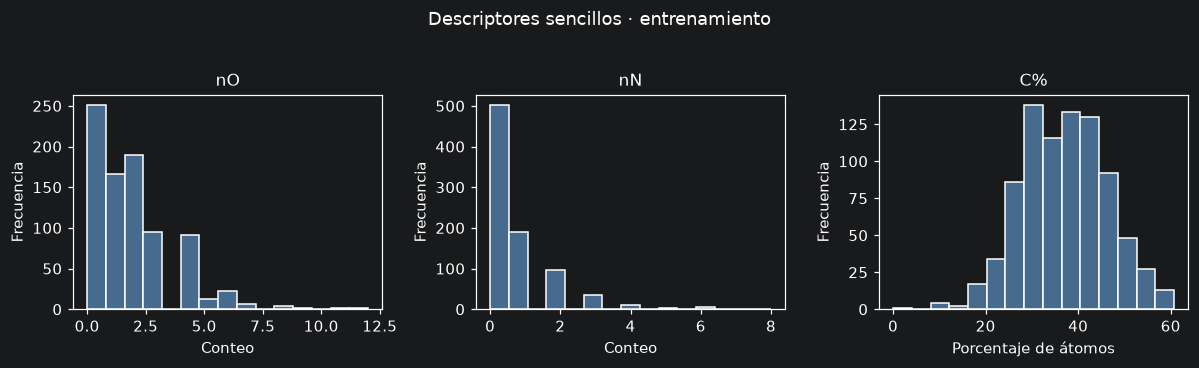

**nO:** el **29.8%** de los valores es cero, lo que ayuda a interpretar la concentración del histograma.

**nN:** el **59.7%** de los valores es cero, lo que ayuda a interpretar la concentración del histograma.

**C%:** el **0.1%** de los valores es cero, lo que ayuda a interpretar la concentración del histograma.

In [39]:
display(X_train.describe().T.round(3))
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, variable in zip(ejes, variables_sencillas):
    ax.hist(X_train[variable], bins=15, color="#476b8e", edgecolor="white")
    ax.set(title=variable, xlabel="Porcentaje de átomos" if variable == "C%" else "Conteo", ylabel="Frecuencia")
fig.suptitle("Descriptores sencillos · entrenamiento", y=1.03)
fig.tight_layout()
plt.show()
for variable in variables_sencillas:
    serie = X_train[variable]
    display(Markdown(
        f"**{variable}:** el **{100 * (serie == 0).mean():.1f}%** de los valores es cero, "
        "lo que ayuda a interpretar la concentración del histograma."
    ))

### Boxplots por clase e inspección de extremos

La línea central de cada caja es la mediana y la caja abarca del primer al tercer cuartil.
Los puntos fuera de los bigotes señalan posibles extremos según la regla de 1.5 veces el rango
intercuartílico ($IQR=Q_3-Q_1$). Estos valores requieren interpretación, pues un descriptor
poco frecuente no implica un error en los datos.

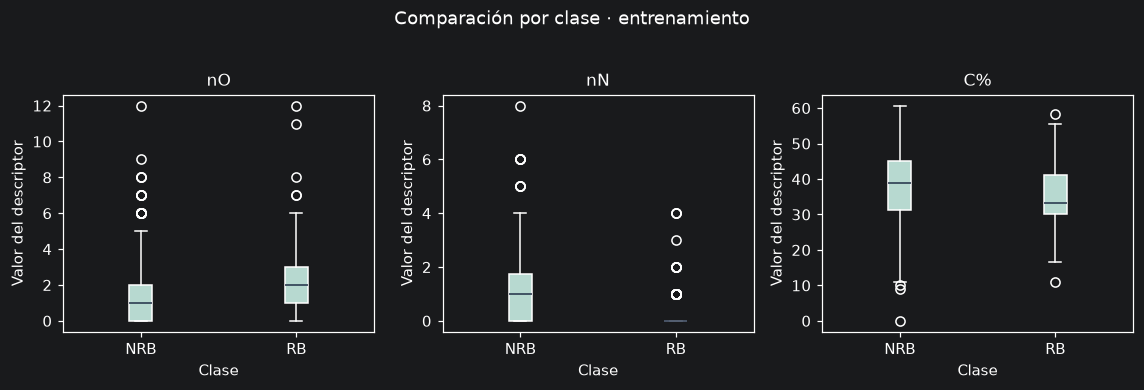

Medianas por clase (leer junto con el solapamiento de las cajas):


,nO,nN,C%
clase,,,
NRB,1.0,1.0,38.9
RB,2.0,0.0,33.3


,Valores fuera de la regla IQR
nO,8
nN,54
C%,5


Se conservan todos estos valores: un conteo molecular poco frecuente puede ser válido. Si el IQR es cero, esta regla puede marcar muchos valores de un descriptor discreto; por sí sola no justifica eliminar registros.

In [40]:
fig, ejes = plt.subplots(1, 3, figsize=(10.5, 3.4))
for ax, variable in zip(ejes, variables_sencillas):
    grupos = [eda.loc[eda["clase"] == clase, variable] for clase in ["NRB", "RB"]]
    ax.boxplot(grupos, tick_labels=["NRB", "RB"], patch_artist=True,
               boxprops={"facecolor": "#b7d9d0"}, medianprops={"color": "#202f46"})
    ax.set(title=variable, xlabel="Clase", ylabel="Valor del descriptor")
fig.suptitle("Comparación por clase · entrenamiento", y=1.03)
fig.tight_layout()
plt.show()

medianas = eda.groupby("clase")[variables_sencillas].median().reindex(["NRB", "RB"])
print("Medianas por clase (leer junto con el solapamiento de las cajas):")
display(medianas)
q1 = X_train[variables_sencillas].quantile(0.25)
q3 = X_train[variables_sencillas].quantile(0.75)
iqr = q3 - q1
posibles_extremos = (
    (X_train[variables_sencillas] < q1 - 1.5 * iqr)
    | (X_train[variables_sencillas] > q3 + 1.5 * iqr)
).sum()
display(posibles_extremos.rename("Valores fuera de la regla IQR").to_frame())
display(Markdown(
    "Se conservan todos estos valores: un conteo molecular poco frecuente puede ser válido. "
    "Si el IQR es cero, esta regla puede marcar muchos valores de un descriptor discreto; "
    "por sí sola no justifica eliminar registros."
))

### Correlaciones de un subconjunto

Se analizaron seis descriptores mediante la correlación de Pearson. Los valores próximos a +1
o −1 indican asociaciones lineales más marcadas; un valor cercano a cero no descarta relaciones
no lineales. El gráfico describe asociaciones entre variables y no se empleó para seleccionar
predictores.

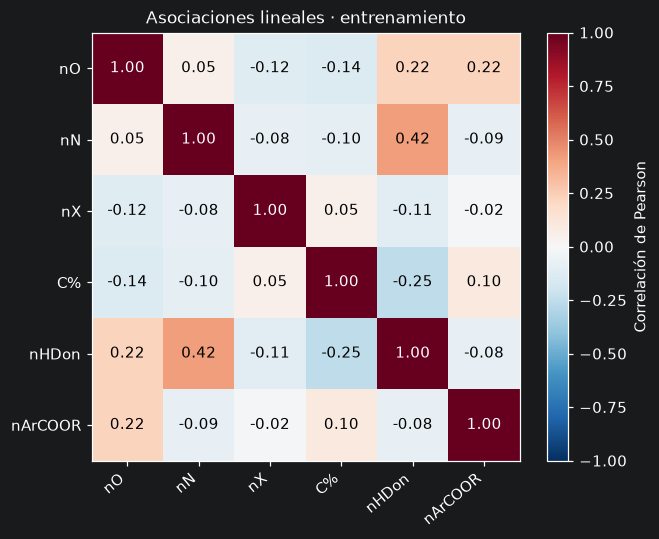

Entre los pares mostrados, **nN y nHDon** presentan la mayor correlación absoluta (**r = 0.42**). Esto indica que parte de la información de estos descriptores está relacionada.

In [41]:
variables_correlacion = ["nO", "nN", "nX", "C%", "nHDon", "nArCOOR"]
correlacion = X_train[variables_correlacion].corr()
fig, ax = plt.subplots(figsize=(6.2, 5))
imagen = ax.imshow(correlacion, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(variables_correlacion)), variables_correlacion, rotation=40, ha="right")
ax.set_yticks(range(len(variables_correlacion)), variables_correlacion)
for i in range(len(variables_correlacion)):
    for j in range(len(variables_correlacion)):
        valor = correlacion.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center",
                color="white" if abs(valor) > 0.6 else "black")
fig.colorbar(imagen, ax=ax, label="Correlación de Pearson")
ax.set_title("Asociaciones lineales · entrenamiento")
fig.tight_layout()
plt.show()
pares = correlacion.where(np.triu(np.ones(correlacion.shape), k=1).astype(bool)).stack()
par_mayor = pares.abs().idxmax()
display(Markdown(
    f"Entre los pares mostrados, **{par_mayor[0]} y {par_mayor[1]}** presentan la mayor "
    f"correlación absoluta (**r = {pares.loc[par_mayor]:.2f}**). "
    "Esto indica que parte de la información de estos descriptores está relacionada."
))

## 7. División de los datos

Se reservó el **20% de los datos para prueba y el 80% para entrenamiento** mediante
`train_test_split`, con `stratify=y` y `random_state=42`. La estratificación mantuvo
aproximadamente las proporciones de RB y NRB en ambos conjuntos.

El entrenamiento se utilizó para explorar los datos, ajustar los modelos y compararlos mediante
cinco particiones internas. La prueba se evaluó después de fijar la selección. La estandarización
se estimó solo con entrenamiento y se conservó la misma división durante todo el análisis.

In [42]:
resumen_division = pd.DataFrame({
    "observaciones": [len(y), len(y_train), len(y_test)],
    "NRB": [(y == 0).sum(), (y_train == 0).sum(), (y_test == 0).sum()],
    "RB": [(y == 1).sum(), (y_train == 1).sum(), (y_test == 1).sum()],
    "% RB": [100 * y.mean(), 100 * y_train.mean(), 100 * y_test.mean()],
}, index=["Total limpio", "Entrenamiento", "Prueba"])
display(resumen_division.round(2))
assert X_train.index.intersection(X_test.index).empty
assert len(X_train) + len(X_test) == len(X)
# La ausencia de conflictos y de duplicados garantiza también ausencia de entradas idénticas.
assert not pd.concat([X_train, X_test]).duplicated().any()

,observaciones,NRB,RB,% RB
Total limpio,1052,698,354,33.65
Entrenamiento,841,558,283,33.65
Prueba,211,140,71,33.65


## 8. Modelado de Machine Learning

Se compararon cinco clasificadores con los mismos 41 predictores y las mismas observaciones
de entrenamiento. Las configuraciones se definieron antes de evaluar el conjunto de prueba.
Se emplearon valores básicos de los hiperparámetros, sin búsquedas de optimización,
ponderaciones de clase ni cambios de umbral.

### Modelo 1. Regresión Logística

Combina linealmente las características y aplica una sigmoide para estimar la probabilidad de RB.  
Permite interpretar el signo de los coeficientes y sirve como modelo de referencia comprensible.  
Se empleó regularización L2 predeterminada, `C=1` y el optimizador L-BFGS.  
El escalado se incluyó en el Pipeline y `max_iter=2000` se fijó como límite para permitir la convergencia.

In [43]:
modelos = {}
modelos["Regresión Logística"] = Pipeline([
    ("escala", StandardScaler()),
    ("clasificador", LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000)),
])

### Modelo 2. K-Nearest Neighbors (KNN)

Para una observación nueva busca las cinco observaciones de entrenamiento más cercanas.  
La clase se decide por mayoría de esos vecinos, con igual peso para cada uno.  
Es intuitivo y permite explorar si moléculas cercanas en descriptores comparten etiqueta.  
Se emplearon la distancia euclidiana y el escalado dentro del Pipeline, porque las unidades afectan las distancias.

In [44]:
modelos["KNN"] = Pipeline([
    ("escala", StandardScaler()),
    ("clasificador", KNeighborsClassifier(n_neighbors=5, weights="uniform", p=2)),
])

### Modelo 3. Support Vector Machine (SVM)

Busca una frontera de separación con un margen amplio entre clases.  
El kernel RBF permite representar una frontera no lineal sin diseñarla manualmente.  
Es útil para comparar una separación flexible con la frontera lineal de Regresión Logística.  
Se fijaron `C=1`, `gamma="scale"` y escalado dentro del Pipeline; estos valores se definieron antes de evaluar la prueba.

In [45]:
modelos["SVM"] = Pipeline([
    ("escala", StandardScaler()),
    ("clasificador", SVC(kernel="rbf", C=1.0, gamma="scale")),
])

### Modelo 4. Gaussian Naive Bayes

Aplica el teorema de Bayes y aproxima cada descriptor con una distribución normal dentro de cada clase.  
Supone independencia condicional de las variables, un supuesto simplificador que puede no cumplirse.  
Se incluye por su sencillez, rapidez y relación directa con Inferencia Bayesiana.  
Se conservaron las escalas originales, ya que estima medias y varianzas propias, con el suavizado de varianza predeterminado.

In [46]:
modelos["Gaussian Naive Bayes"] = Pipeline([
    ("clasificador", GaussianNB(var_smoothing=1e-9)),
])

### Modelo 5. Random Forest

Combina votos de árboles entrenados con muestras aleatorias del entrenamiento y subconjuntos de variables.  
Puede representar relaciones no lineales e interacciones sin estandarización.  
Es una comparación útil frente a métodos lineales, de distancia y probabilísticos.  
Se fijaron 100 árboles y semilla 42; su interpretación global es menos directa y también puede sobreajustar.

In [47]:
modelos["Random Forest"] = Pipeline([
    ("clasificador", RandomForestClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=1)),
])

# Ajustes definitivos sobre TODO el entrenamiento; el test sigue reservado.
modelos_entrenados = {}
tiempos_entrenamiento = {}
for nombre, pipeline in modelos.items():
    modelo = clone(pipeline)
    inicio = perf_counter()
    modelo.fit(X_train, y_train)
    tiempos_entrenamiento[nombre] = perf_counter() - inicio
    modelos_entrenados[nombre] = modelo

display(pd.Series(tiempos_entrenamiento, name="Ajuste sobre entrenamiento (s)").to_frame().round(4))
print("Modelos ajustados:", len(modelos_entrenados))

,Ajuste sobre entrenamiento (s)
Regresión Logística,0.0122
KNN,0.0039
SVM,0.0228
Gaussian Naive Bayes,0.0024
Random Forest,0.1924


Modelos ajustados: 5


## 9. Evaluación

Se consideró **RB = 1** como clase positiva. **TP** son RB predichas RB; **TN**, NRB predichas NRB;
**FP**, NRB predichas RB; **FN**, RB predichas NRB.

| Métrica | Fórmula | Lectura sencilla |
|---|---|---|
| Accuracy | $(TP+TN)/(TP+TN+FP+FN)$ | De todas las predicciones, ¿qué fracción fue correcta? |
| Precision de RB | $TP/(TP+FP)$ | De las predichas como RB, ¿qué fracción era realmente RB? |
| Recall de RB | $TP/(TP+FN)$ | De todas las RB reales, ¿qué fracción se identificó? |
| F1 de RB | $2PR/(P+R)$ | Equilibra precision $P$ y recall $R$ mediante su media armónica |

**Ejemplo didáctico, no un resultado del dataset:** si de 10 predicciones RB aciertan 8, la precision
es 0.80. Si existían 16 RB reales y se identificaron 8, el recall es 0.50 y F1 es aproximadamente 0.62.
La matriz de confusión indica además los tipos concretos de error.

**Regla de selección previa:** mayor **F1 medio de RB** en cinco particiones estratificadas del
entrenamiento. Si hay igualdad exacta, se conserva el orden de presentación de los modelos.
Accuracy, precision y recall son complementarias. La desviación estándar de F1 describe variación
entre particiones; no es un intervalo de confianza ni una prueba de superioridad estadística.

In [48]:
validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
metricas_cv = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "f1": make_scorer(f1_score, pos_label=1, zero_division=0),
}
filas_cv = []
f1_por_particion = {}
for nombre, pipeline in modelos.items():
    # cross_validate clona el Pipeline: ningún escalador ve su partición de validación.
    puntuaciones = cross_validate(
        pipeline, X_train, y_train, cv=validacion, scoring=metricas_cv,
        n_jobs=1, error_score="raise",
    )
    f1_por_particion[nombre] = puntuaciones["test_f1"]
    filas_cv.append({
        "Modelo": nombre,
        "Accuracy CV": puntuaciones["test_accuracy"].mean(),
        "Precision CV": puntuaciones["test_precision"].mean(),
        "Recall CV": puntuaciones["test_recall"].mean(),
        "F1 CV": puntuaciones["test_f1"].mean(),
        "DE F1 CV": puntuaciones["test_f1"].std(ddof=1),
    })
resultados_cv = pd.DataFrame(filas_cv).set_index("Modelo")
ranking_cv = resultados_cv.sort_values("F1 CV", ascending=False, kind="stable")
modelo_seleccionado = ranking_cv.index[0]  # Se fija ANTES de calcular métricas de prueba.
display(ranking_cv.round(4))
display(Markdown(
    f"**Modelo seleccionado por validación cruzada: {modelo_seleccionado}.** "
    "Las columnas CV corresponden a las particiones internas del entrenamiento."
))

,Accuracy CV,Precision CV,Recall CV,F1 CV,DE F1 CV
Modelo,,,,,
SVM,0.8835,0.8539,0.7917,0.8211,0.0375
Regresión Logística,0.8799,0.8255,0.8164,0.8205,0.0231
Random Forest,0.8787,0.8530,0.7742,0.8109,0.0358
KNN,0.8538,0.7751,0.7987,0.7863,0.0384
Gaussian Naive Bayes,0.6766,0.5115,0.9506,0.6648,0.0222


**Modelo seleccionado por validación cruzada: SVM.** Las columnas CV corresponden a las particiones internas del entrenamiento.

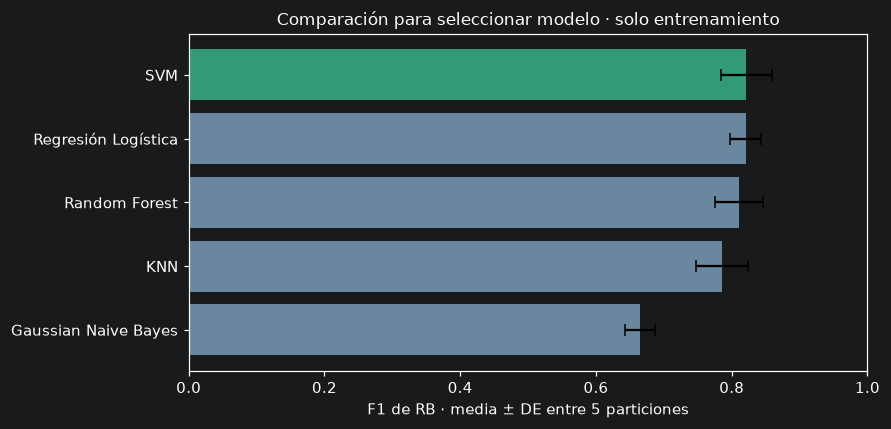

In [49]:
fig, ax = plt.subplots(figsize=(8.2, 4))
posiciones = np.arange(len(ranking_cv))
ax.barh(posiciones, ranking_cv["F1 CV"], xerr=ranking_cv["DE F1 CV"],
        color=["#329979"] + ["#6b879f"] * (len(ranking_cv) - 1), capsize=4)
ax.set_yticks(posiciones, ranking_cv.index)
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel="F1 de RB · media ± DE entre 5 particiones",
       title="Comparación para seleccionar modelo · solo entrenamiento")
fig.tight_layout()
plt.show()

### Evaluación final en prueba

Después de seleccionar el modelo mediante validación cruzada, se evaluaron los cinco
clasificadores en el conjunto de prueba. La tabla conserva el orden de validación cruzada.
Se utilizó `zero_division=0` para informar cero cuando una métrica tuviera denominador nulo.

In [50]:
predicciones_prueba = {}
filas_prueba = []
for nombre, modelo in modelos_entrenados.items():
    prediccion = modelo.predict(X_test)
    predicciones_prueba[nombre] = prediccion
    filas_prueba.append({
        "Modelo": nombre,
        "Accuracy prueba": accuracy_score(y_test, prediccion),
        "Precision prueba": precision_score(y_test, prediccion, pos_label=1, zero_division=0),
        "Recall prueba": recall_score(y_test, prediccion, pos_label=1, zero_division=0),
        "F1 prueba": f1_score(y_test, prediccion, pos_label=1, zero_division=0),
    })
resultados_prueba = pd.DataFrame(filas_prueba).set_index("Modelo")
tabla_comparativa = (
    resultados_cv[["F1 CV", "DE F1 CV"]]
    .join(resultados_prueba)
    .join(pd.Series(tiempos_entrenamiento, name="Ajuste (s)"))
    .loc[ranking_cv.index]
)
display(tabla_comparativa.round(4))

# Referencia aritmética; el baseline ingenuo separado se evalúa más adelante.
accuracy_siempre_nrb = float((y_test == 0).mean())
display(Markdown(
    "Los tiempos corresponden al ajuste completo de cada Pipeline sobre entrenamiento; "
    "excluyen la validación cruzada y la predicción, y dependen del equipo."
))

,F1 CV,DE F1 CV,Accuracy prueba,Precision prueba,Recall prueba,F1 prueba,Ajuste (s)
Modelo,,,,,,,
SVM,0.8211,0.0375,0.8531,0.7941,0.7606,0.7770,0.0228
Regresión Logística,0.8205,0.0231,0.8626,0.8088,0.7746,0.7914,0.0122
Random Forest,0.8109,0.0358,0.8863,0.8615,0.7887,0.8235,0.1924
KNN,0.7863,0.0384,0.8720,0.7895,0.8451,0.8163,0.0039
Gaussian Naive Bayes,0.6648,0.0222,0.6825,0.5154,0.9437,0.6667,0.0024


Los tiempos corresponden al ajuste completo de cada Pipeline sobre entrenamiento; excluyen la validación cruzada y la predicción, y dependen del equipo.

### Matrices de confusión de los cinco clasificadores

Las matrices corresponden al mismo conjunto de prueba. Las filas indican la clase real y las
columnas la predicha, en el orden NRB (0), RB (1). La diagonal contiene los aciertos: verdaderos
negativos (**VN**) y verdaderos positivos (**VP**). Las otras celdas muestran los falsos positivos
(**FP**) y falsos negativos (**FN**).

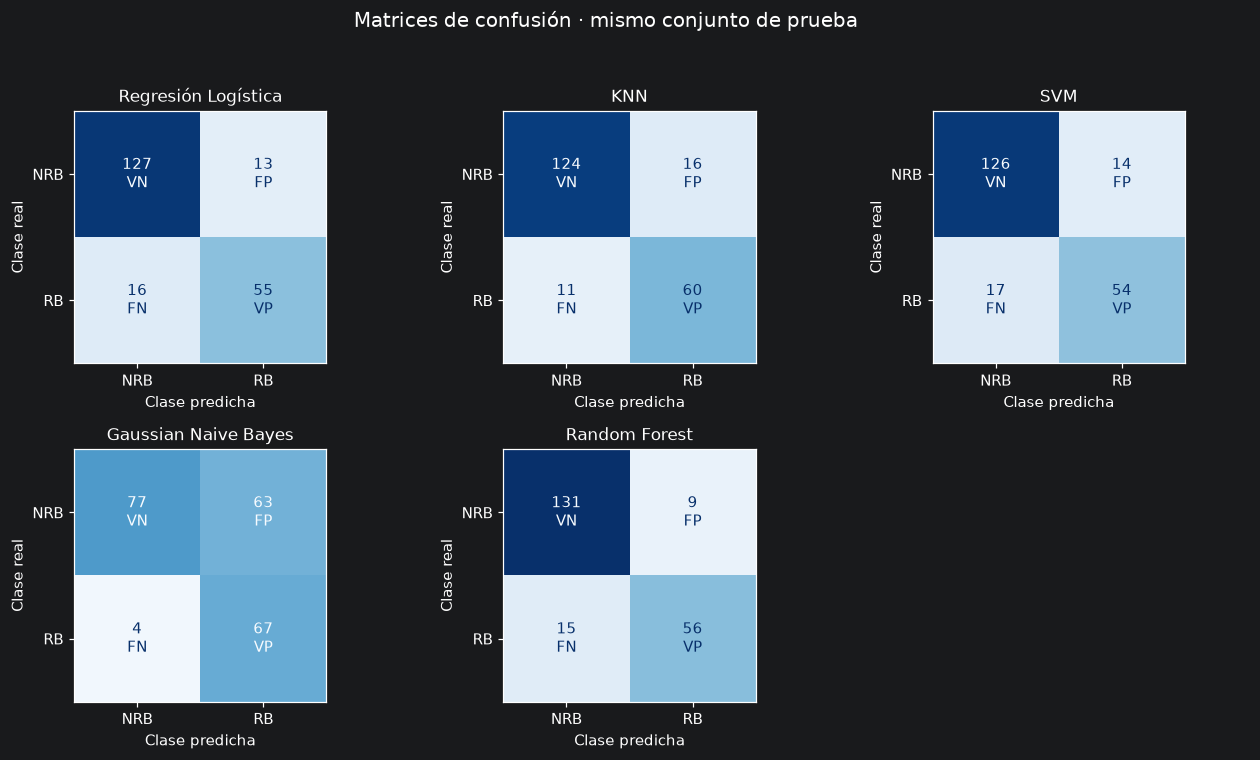

En la matriz de **SVM**, los falsos positivos corresponden a sustancias NRB clasificadas como RB, mientras que los falsos negativos son RB clasificadas como NRB. Los primeros atribuyen facilidad de biodegradación a sustancias sin esa etiqueta experimental; los segundos dejan sin reconocer sustancias RB. Su importancia depende del uso previsto.

In [51]:
prediccion_seleccionada = predicciones_prueba[modelo_seleccionado]
matriz = confusion_matrix(y_test, prediccion_seleccionada, labels=[0, 1])
tn, fp, fn, tp = matriz.ravel()
# Se amplía la figura del modelo seleccionado sin modificar sus predicciones.
nombres_evaluacion = list(modelos_entrenados)
assert len(nombres_evaluacion) == 5
assert set(nombres_evaluacion) == set(predicciones_prueba)
assert X_test.index.equals(y_test.index)
matrices_prueba = {
    nombre_modelo: confusion_matrix(y_test, predicciones_prueba[nombre_modelo], labels=[0, 1])
    for nombre_modelo in nombres_evaluacion
}
etiquetas_celdas = np.array([["VN", "FP"], ["FN", "VP"]])
maximo_matrices = max(matriz_modelo.max() for matriz_modelo in matrices_prueba.values())
fig_matrices, ejes_matrices = plt.subplots(2, 3, figsize=(12, 7))
for eje_modelo, nombre_modelo in zip(ejes_matrices.ravel(), nombres_evaluacion):
    matriz_modelo = matrices_prueba[nombre_modelo]
    assert matriz_modelo.shape == (2, 2) and matriz_modelo.sum() == len(y_test)
    visualizacion = ConfusionMatrixDisplay(matriz_modelo, display_labels=["NRB", "RB"])
    visualizacion.plot(
        ax=eje_modelo, cmap="Blues", colorbar=False, values_format="d",
        im_kw={"vmin": 0, "vmax": maximo_matrices},
    )
    for fila_matriz in range(2):
        for columna_matriz in range(2):
            visualizacion.text_[fila_matriz, columna_matriz].set_text(
                f"{matriz_modelo[fila_matriz, columna_matriz]}\n"
                f"{etiquetas_celdas[fila_matriz, columna_matriz]}"
            )
    eje_modelo.set(
        title=nombre_modelo, xlabel="Clase predicha", ylabel="Clase real",
    )
ejes_matrices.ravel()[-1].set_axis_off()
fig_matrices.suptitle("Matrices de confusión · mismo conjunto de prueba", fontsize=13)
fig_matrices.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

display(Markdown(
    f"En la matriz de **{modelo_seleccionado}**, los falsos positivos corresponden a sustancias "
    "NRB clasificadas como RB, mientras que los falsos negativos son RB clasificadas como NRB. "
    "Los primeros atribuyen facilidad de biodegradación a sustancias sin esa etiqueta experimental; "
    "los segundos dejan sin reconocer sustancias RB. Su importancia depende del uso previsto."
))

#### Interpretación conjunta de las matrices

La tabla resume los aciertos y los tipos de error en valores absolutos. Al utilizar el mismo
conjunto de prueba, estas cantidades pueden compararse directamente entre los clasificadores.

In [52]:
filas_errores = []
for nombre_modelo, matriz_modelo in matrices_prueba.items():
    vn_modelo, fp_modelo, fn_modelo, vp_modelo = matriz_modelo.ravel()
    filas_errores.append({
        "Modelo": nombre_modelo, "VN": vn_modelo, "FP": fp_modelo,
        "FN": fn_modelo, "VP": vp_modelo, "Aciertos": vn_modelo + vp_modelo,
    })
    precision_matriz = vp_modelo / (vp_modelo + fp_modelo) if vp_modelo + fp_modelo else 0.0
    recall_matriz = vp_modelo / (vp_modelo + fn_modelo) if vp_modelo + fn_modelo else 0.0
    f1_matriz = (
        2 * precision_matriz * recall_matriz / (precision_matriz + recall_matriz)
        if precision_matriz + recall_matriz else 0.0
    )
    assert np.allclose(
        [(vn_modelo + vp_modelo) / len(y_test), precision_matriz, recall_matriz, f1_matriz],
        resultados_prueba.loc[nombre_modelo].to_numpy(),
    )
resumen_matrices_prueba = pd.DataFrame(filas_errores).set_index("Modelo")
display(resumen_matrices_prueba)
modelo_mas_aciertos = resumen_matrices_prueba["Aciertos"].idxmax()
modelo_mas_fp = resumen_matrices_prueba["FP"].idxmax()
modelo_mas_fn = resumen_matrices_prueba["FN"].idxmax()
modelo_menos_fp = resumen_matrices_prueba["FP"].idxmin()
modelo_mayor_recall = resultados_prueba["Recall prueba"].idxmax()
errores_mayor_recall = resumen_matrices_prueba.loc[modelo_mayor_recall]
display(Markdown(
    f"**{modelo_menos_fp}** produjo menos falsos positivos y **{modelo_mas_fn}** "
    "presentó más falsos negativos. La tabla permite distinguir estos tipos de error "
    "aunque dos clasificadores tengan un número similar de aciertos."
))

,VN,FP,FN,VP,Aciertos
Modelo,,,,,
Regresión Logística,127,13,16,55,182
KNN,124,16,11,60,184
SVM,126,14,17,54,180
Gaussian Naive Bayes,77,63,4,67,144
Random Forest,131,9,15,56,187


**Random Forest** produjo menos falsos positivos y **SVM** presentó más falsos negativos. La tabla permite distinguir estos tipos de error aunque dos clasificadores tengan un número similar de aciertos.

### Curvas ROC de los cinco clasificadores

La curva ROC representa la tasa de verdaderos positivos (**TPR**, equivalente al recall de RB)
frente a la tasa de falsos positivos (**FPR**, proporción de NRB clasificadas como RB) al recorrer
los posibles umbrales de una puntuación. Este recorrido describe el comportamiento del modelo;
no cambia los umbrales de las predicciones utilizadas en las matrices.

El **AUC** resume la capacidad de distinguir RB de NRB mediante el orden de sus puntuaciones:
un valor de 1 corresponde a separación perfecta en esta muestra y 0.5 a la referencia aleatoria.
No equivale a accuracy ni demuestra que las probabilidades estén calibradas.

Se utiliza la probabilidad de RB de los modelos que ofrecen predict_proba. Para SVM se emplea
decision_function: valores mayores indican mayor tendencia hacia RB, pero no son probabilidades.
Las curvas no se calculan con las etiquetas binarias de predict.

Implementación: documentación oficial de
[roc_curve](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html)
y [roc_auc_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html).

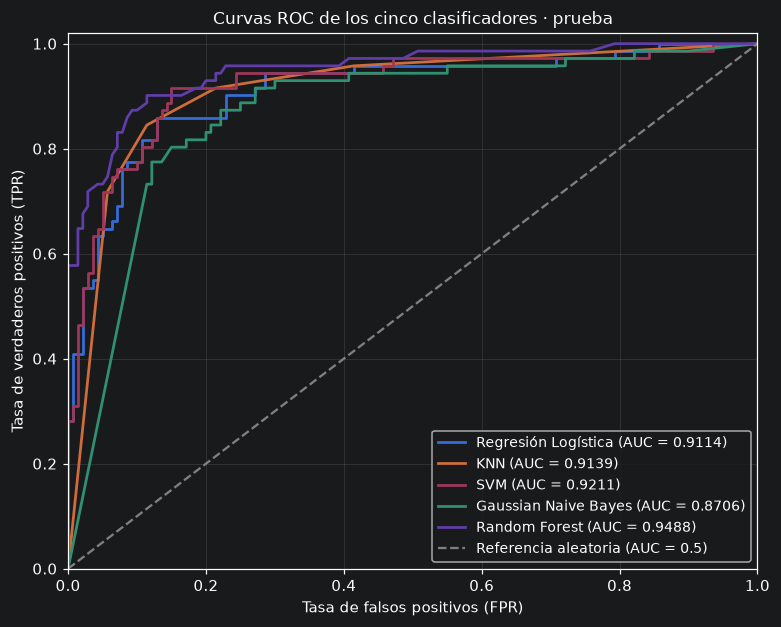

In [53]:
from sklearn.metrics import roc_curve, roc_auc_score

puntuaciones_roc = {}
origen_puntuaciones_roc = {}
curvas_roc = {}
areas_roc = {}
fig_roc, ax_roc = plt.subplots(figsize=(7.2, 5.8))
for nombre_modelo in nombres_evaluacion:
    modelo_roc = modelos_entrenados[nombre_modelo]
    assert list(modelo_roc.classes_) == [0, 1]
    if hasattr(modelo_roc, "predict_proba"):
        columna_rb = int(np.flatnonzero(modelo_roc.classes_ == 1)[0])
        puntuacion_rb = modelo_roc.predict_proba(X_test)[:, columna_rb]
        origen_puntuaciones_roc[nombre_modelo] = "predict_proba de RB"
    elif hasattr(modelo_roc, "decision_function"):
        puntuacion_rb = modelo_roc.decision_function(X_test)
        origen_puntuaciones_roc[nombre_modelo] = "decision_function hacia RB"
    else:
        raise ValueError(f"{nombre_modelo} no ofrece puntuaciones adecuadas para ROC.")
    puntuacion_rb = np.asarray(puntuacion_rb)
    assert puntuacion_rb.shape == (len(y_test),) and np.isfinite(puntuacion_rb).all()
    puntuaciones_roc[nombre_modelo] = puntuacion_rb
    fpr_modelo, tpr_modelo, _ = roc_curve(y_test, puntuacion_rb, pos_label=1)
    curvas_roc[nombre_modelo] = (fpr_modelo, tpr_modelo)
    areas_roc[nombre_modelo] = roc_auc_score(y_test, puntuacion_rb)
    ax_roc.plot(
        fpr_modelo, tpr_modelo, linewidth=1.8,
        label=f"{nombre_modelo} (AUC = {areas_roc[nombre_modelo]:.4f})",
    )
ax_roc.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Referencia aleatoria (AUC = 0.5)")
ax_roc.set(
    xlim=(0, 1), ylim=(0, 1.02),
    xlabel="Tasa de falsos positivos (FPR)", ylabel="Tasa de verdaderos positivos (TPR)",
    title="Curvas ROC de los cinco clasificadores · prueba",
)
ax_roc.legend(loc="lower right", fontsize=9)
ax_roc.grid(alpha=0.2)
fig_roc.tight_layout()
plt.show()
auc_prueba = pd.Series(areas_roc, name="AUC prueba")
assert len(matrices_prueba) == len(curvas_roc) == len(auc_prueba) == 5
assert len(ax_roc.lines) == 6  # Cinco modelos y la diagonal de referencia.
assert all(0 <= valor_auc <= 1 for valor_auc in auc_prueba)

In [54]:
orden_auc = auc_prueba.sort_values(ascending=False, kind="stable")
modelo_mayor_auc = orden_auc.index[0]
segundo_modelo_auc = orden_auc.index[1]
diferencia_auc_primeros = float(orden_auc.iloc[0] - orden_auc.iloc[1])
amplitud_auc = float(orden_auc.max() - orden_auc.min())
coincidencia_roc_matrices = (
    f"El mayor AUC correspondió también a {modelo_mas_aciertos}, que obtuvo más aciertos "
    "en las matrices de confusión."
    if modelo_mayor_auc == modelo_mas_aciertos else
    f"El mayor AUC correspondió a {modelo_mayor_auc}, mientras que {modelo_mas_aciertos} "
    "obtuvo más aciertos en las matrices de confusión."
)
display(Markdown(
    f"Las curvas de **{modelo_mayor_auc}** y **{segundo_modelo_auc}** presentan los mayores AUC. "
    "La proximidad entre algunas curvas requiere cautela al interpretar sus diferencias. "
    "Un mayor AUC no implica necesariamente un mayor recall en el umbral de clasificación utilizado."
))

Las curvas de **Random Forest** y **SVM** presentan los mayores AUC. La proximidad entre algunas curvas requiere cautela al interpretar sus diferencias. Un mayor AUC no implica necesariamente un mayor recall en el umbral de clasificación utilizado.

### Comparación con una predicción básica

Para comprobar si los algoritmos ofrecen mejores resultados que una clasificación sencilla,
se utilizó `DummyClassifier`, que predice siempre la clase mayoritaria del entrenamiento.
En estos datos corresponde a NRB. Aunque esta regla consigue aciertos, no identifica ninguna
sustancia RB, como muestran las tablas. La comparación permite valorar la utilidad de los
cinco clasificadores y la importancia de otras métricas además de accuracy. Se trata de una
referencia de comparación, no de un sexto modelo principal.

In [55]:
from sklearn.dummy import DummyClassifier

baseline_ingenuo = Pipeline([
    ("clasificador", DummyClassifier(strategy="most_frequent")),
])
puntuaciones_baseline = cross_validate(
    baseline_ingenuo, X_train, y_train, cv=validacion, scoring=metricas_cv,
    n_jobs=1, error_score="raise",
)
baseline_ingenuo.fit(X_train, y_train)
prediccion_baseline = baseline_ingenuo.predict(X_test)
resultados_baseline = pd.DataFrame({
    "Accuracy": [puntuaciones_baseline["test_accuracy"].mean(),
                 accuracy_score(y_test, prediccion_baseline)],
    "Precision RB": [puntuaciones_baseline["test_precision"].mean(),
                     precision_score(y_test, prediccion_baseline, pos_label=1, zero_division=0)],
    "Recall RB": [puntuaciones_baseline["test_recall"].mean(),
                  recall_score(y_test, prediccion_baseline, pos_label=1, zero_division=0)],
    "F1 RB": [puntuaciones_baseline["test_f1"].mean(),
              f1_score(y_test, prediccion_baseline, pos_label=1, zero_division=0)],
}, index=["Baseline · CV de entrenamiento (media)", "Baseline · prueba reservada"])
display(resultados_baseline.round(4))
matriz_baseline = confusion_matrix(y_test, prediccion_baseline, labels=[0, 1])
display(pd.DataFrame(
    matriz_baseline, index=["Real NRB", "Real RB"],
    columns=["Predicha NRB", "Predicha RB"],
))
clase_mayoritaria = int(y_train.mode().iloc[0])
nombre_mayoritaria = {0: "NRB", 1: "RB"}[clase_mayoritaria]
display(Markdown(
    f"El baseline predice siempre **{nombre_mayoritaria}**. "
    "La matriz muestra que sus aciertos se concentran en esa clase, lo que ilustra "
    "la importancia de evaluar también el reconocimiento de RB."
))
assert len(modelos) == len(ranking_cv) == 5
assert np.all(prediccion_baseline == clase_mayoritaria)

,Accuracy,Precision RB,Recall RB,F1 RB
Baseline · CV de entrenamiento (media),0.6635,0.0,0.0,0.0
Baseline · prueba reservada,0.6635,0.0,0.0,0.0


,Predicha NRB,Predicha RB
Real NRB,140,0
Real RB,71,0


El baseline predice siempre **NRB**. La matriz muestra que sus aciertos se concentran en esa clase, lo que ilustra la importancia de evaluar también el reconocimiento de RB.

## 10. Comparación de modelos

La sección 9 presenta el rendimiento y los tiempos de ajuste. La siguiente tabla resume
las diferencias conceptuales entre los clasificadores:

| Modelo | Interpretabilidad y complejidad | Ventaja | Limitación |
|---|---|---|---|
| Regresión Logística | Coeficientes; frontera lineal | Relación matemática clara entre descriptores y probabilidad | No representa por sí sola todas las relaciones no lineales; coeficientes afectados por correlaciones |
| KNN | Vecinos; regla sencilla, conserva los datos | Comparación intuitiva por cercanía | Sensible a escala y variables poco útiles; predecir puede costar más que ajustar |
| SVM RBF | Frontera no lineal; interpretación global difícil | Frontera flexible con control de margen | Sensible a escala y configuración del kernel |
| Gaussian Naive Bayes | Medias, varianzas y probabilidades previas | Ajuste directo y fácil de explicar con Bayes | Normalidad e independencia condicional son aproximaciones, especialmente con conteos y presencias |
| Random Forest | Muchos árboles; interpretación global menos directa | Captura interacciones y no necesita escala | Más componentes y riesgo de sobreajuste |

La tabla siguiente muestra la variación de F1 entre particiones como una referencia de estabilidad.
Los tiempos de ajuste deben interpretarse según el funcionamiento de cada método: KNN almacena
los ejemplos y realiza buena parte del trabajo durante la predicción.

In [56]:
primero, segundo = ranking_cv.index[:2]

diferencia_cv = ranking_cv.loc[primero, "F1 CV"] - ranking_cv.loc[segundo, "F1 CV"]

escala_variacion = max(ranking_cv.loc[primero, "DE F1 CV"], ranking_cv.loc[segundo, "DE F1 CV"])

display(pd.DataFrame(f1_por_particion, index=[f"Partición {i}" for i in range(1, 6)]).T.round(4))

diferencia_svm_logistica = abs(
    resultados_cv.loc["SVM", "F1 CV"] - resultados_cv.loc["Regresión Logística", "F1 CV"]
)

metricas_superadas_rf = [
    metrica for metrica in resultados_prueba.columns
    if resultados_prueba.loc["Random Forest", metrica]
    > resultados_prueba.loc[modelo_seleccionado, metrica]
]

,Partición 1,Partición 2,Partición 3,Partición 4,Partición 5
Regresión Logística,0.8174,0.8182,0.8000,0.8073,0.8596
KNN,0.7434,0.8067,0.7458,0.8174,0.8182
SVM,0.8182,0.8381,0.7611,0.8257,0.8624
Gaussian Naive Bayes,0.6506,0.6708,0.6353,0.6923,0.6752
Random Forest,0.7963,0.7961,0.7818,0.8727,0.8073


### Consistencia de la evaluación gráfica

Se comprobó que las matrices y las métricas correspondieran a las mismas predicciones y
observaciones de prueba, y que se incluyeran los cinco clasificadores en la evaluación gráfica.

In [57]:
modelo_mayor_f1_prueba = resultados_prueba["F1 prueba"].idxmax()
metricas_seleccionado_graficas = resultados_prueba.loc[modelo_seleccionado]
assert np.array_equal(matriz, matrices_prueba[modelo_seleccionado])
assert X_test.index.equals(y_test.index)
assert len(modelos_entrenados) == len(predicciones_prueba) == 5
print("Verificación gráfica correcta: cinco matrices, cinco curvas ROC y métricas consistentes.")

Verificación gráfica correcta: cinco matrices, cinco curvas ROC y métricas consistentes.


## 11. Desarrollo matemático

### 11.1. Desarrollo matemático de Regresión Logística

Se modeló la probabilidad de que una sustancia pertenezca a RB a partir de sus 41 variables
independientes o descriptores. Para la observación $i$, la combinación lineal es:

$$z_i=\beta_0+\sum_{j=1}^{41}\beta_jx'_{ij},\qquad
x'_{ij}=\frac{x_{ij}-\mu_{j,\mathrm{train}}}{s_{j,\mathrm{train}}}.$$

$x_{ij}$ es el valor del descriptor $j$ y $x'_{ij}$ su valor estandarizado con la media
$\mu_{j,\mathrm{train}}$ y la desviación estándar $s_{j,\mathrm{train}}$ del entrenamiento.
$\beta_j$ es su coeficiente y $\beta_0$ el intercepto. La función sigmoide transforma $z_i$
en una probabilidad estimada:

$$p_i=\sigma(z_i)=\frac{1}{1+e^{-z_i}}\approx P(Y_i=1\mid\mathbf{x}_i).$$

$\mathbf{x}_i$ reúne los descriptores, $e$ es la base del logaritmo natural y $Y_i=1$ representa
RB. La probabilidad $p_i$ se refiere a esa etiqueta, no al porcentaje de materia que se degradará.

Los coeficientes se estimaron reduciendo la log-loss, que penaliza las predicciones incorrectas,
especialmente cuando se realizan con mucha confianza:

$$L(\boldsymbol\beta)=-\frac{1}{m}\sum_{i=1}^{m}
\left[y_i\ln(p_i)+(1-y_i)\ln(1-p_i)\right].$$

$m$ es el número de observaciones de entrenamiento, $y_i\in\{0,1\}$ la etiqueta real y $\ln$
el logaritmo natural. Se incluyó regularización L2, cuyo objetivo puede expresarse como:

$$J(\boldsymbol\beta)=L(\boldsymbol\beta)+\frac{\lambda}{2}\sum_{j=1}^{41}\beta_j^2,
\qquad \lambda>0.$$

$\lambda$ controla la penalización de coeficientes grandes; el intercepto no se penaliza en esta
configuración. En scikit-learn, `C` controla inversamente la regularización y su equivalencia con
$\lambda$ depende de cómo se normaliza el objetivo. Se empleó `C=1` y el optimizador **L-BFGS**,
que utiliza gradientes y una aproximación de la curvatura para reducir el costo iterativamente.

Los coeficientes actúan sobre el logaritmo de las *odds*, definidas como $p_i/(1-p_i)$:

$$\ln\frac{p_i}{1-p_i}=z_i.$$

Al aumentar un descriptor en una desviación estándar, manteniendo fijos los demás, las odds
se multiplican por $e^{\beta_j}$. La clasificación final utiliza el umbral predeterminado de 0.5:

$$\widehat y_i=\begin{cases}1\;(RB),&p_i>0.5,\\0\;(NRB),&p_i\leq0.5.\end{cases}$$

$\widehat y_i$ es la clase predicha. En un empate exacto se asigna NRB, de acuerdo con el orden
de clases de esta implementación.

#### Aplicación a los datos

Se consultaron los parámetros de la Regresión Logística ajustada con el conjunto de entrenamiento.
La tabla presenta `nO`, `nN` y `C%` junto con los coeficientes de mayor valor absoluto.

En el modelo ajustado, `nO` y `C%` presentan coeficientes positivos, mientras que `nN` tiene signo
negativo. Un signo positivo aumenta la tendencia hacia RB y uno negativo la reduce, manteniendo
fijos los demás descriptores. Una mayor magnitud implica un cambio mayor en las log-odds ante
el mismo aumento de una desviación estándar. Estas asociaciones dependen del modelo y de las
relaciones entre variables; no demuestran causalidad.

In [58]:
# Parámetros de la Regresión Logística ya ajustada en entrenamiento.
pipeline_logistico = modelos_entrenados["Regresión Logística"]
escalador_logistico = pipeline_logistico.named_steps["escala"]
clasificador_logistico = pipeline_logistico.named_steps["clasificador"]
nombres_entrenamiento = list(pipeline_logistico.feature_names_in_)
assert nombres_entrenamiento == list(X_train.columns) == descriptores
assert list(escalador_logistico.feature_names_in_) == nombres_entrenamiento
assert clasificador_logistico.coef_.shape == (1, 41)
assert list(clasificador_logistico.classes_) == [0, 1]

coeficientes_logisticos = clasificador_logistico.coef_[0]
intercepto_logistico = float(clasificador_logistico.intercept_[0])
tabla_41_coeficientes = pd.DataFrame({
    "Posición UCI": np.arange(1, 42),
    "Coeficiente estandarizado": coeficientes_logisticos,
    "Multiplicador de odds": np.exp(coeficientes_logisticos),
}, index=pd.Index(nombres_entrenamiento, name="Descriptor"))
orden_magnitud = tabla_41_coeficientes["Coeficiente estandarizado"].abs().sort_values(
    ascending=False, kind="stable",
).index
cinco_coeficientes_mayores = tabla_41_coeficientes.loc[orden_magnitud[:5]].copy()
cinco_coeficientes_mayores["Valor absoluto"] = cinco_coeficientes_mayores["Coeficiente estandarizado"].abs()
descriptores_resumen = list(dict.fromkeys(
    ["nO", "nN", "C%"] + list(cinco_coeficientes_mayores.index)
))
tabla_coeficientes = tabla_41_coeficientes.loc[
    descriptores_resumen, ["Coeficiente estandarizado", "Multiplicador de odds"],
]
display(Markdown(
    f"El ajuste se realizó con **{escalador_logistico.n_samples_seen_:.0f} observaciones** y "
    f"**{len(nombres_entrenamiento)} variables independientes**. "
    fr"El intercepto obtenido fue $\beta_0={intercepto_logistico:.6f}$."
))
display(tabla_coeficientes.round(6))

El ajuste se realizó con **841 observaciones** y **41 variables independientes**. El intercepto obtenido fue $\beta_0=-2.350795$.

,Coeficiente estandarizado,Multiplicador de odds
Descriptor,,
nO,0.631167,1.879802
nN,-0.667031,0.513230
C%,1.337331,3.808864
nCb-,-1.376867,0.252368
HyWi_B(m),-1.224965,0.293768
NssssC,-1.208186,0.298739
SM6_L,1.042925,2.837503


### 11.2. Desarrollo matemático de Gaussian Naive Bayes

Para una sustancia con vector de descriptores $\mathbf{x}$, el teorema de Bayes permite estimar
la probabilidad de cada clase $c\in\{0,1\}$, donde 0 representa NRB y 1 representa RB:

$$P(Y=c\mid\mathbf{x})=
\frac{f(\mathbf{x}\mid Y=c)P(Y=c)}{f(\mathbf{x})}.$$

$P(Y=c)$ es la probabilidad previa de la clase y $f(\mathbf{x}\mid Y=c)$ es la densidad de los
descriptores dentro de ella. El denominador $f(\mathbf{x})$ normaliza las probabilidades. El
resultado es la probabilidad posterior de pertenecer a la clase después de observar los datos.

El método supone independencia condicional: conocida la clase, los descriptores aportan
información de manera independiente. Esto simplifica la densidad conjunta de las 41 variables:

$$f(\mathbf{x}\mid Y=c)\approx\prod_{j=1}^{41}f(x_j\mid Y=c).$$

$x_j$ es el valor del descriptor $j$. Gaussian Naive Bayes aproxima su distribución en cada
clase mediante una densidad normal:

$$f(x_j\mid Y=c)=\frac{1}{\sqrt{2\pi\sigma^2_{cj}}}
\exp\left(-\frac{(x_j-\mu_{cj})^2}{2\sigma^2_{cj}}\right).$$

$\mu_{cj}$ es la media del descriptor $j$ en la clase $c$, $\sigma^2_{cj}$ su varianza y $\pi$
la constante matemática. La densidad indica qué tan compatible es un valor con esa distribución;
no es la probabilidad de observar exactamente ese valor.

Con $m$ observaciones de entrenamiento, de las cuales $n_c$ pertenecen a la clase $c$, los
parámetros se estiman como:

$$\widehat P(Y=c)=\frac{n_c}{m},\qquad
\widehat\mu_{cj}=\frac{1}{n_c}\sum_{i:y_i=c}x_{ij},$$

$$\widehat\sigma^2_{cj}=\frac{1}{n_c}\sum_{i:y_i=c}(x_{ij}-\widehat\mu_{cj})^2.$$

$x_{ij}$ es el valor observado y $y_i$ su clase real. El acento sobre los parámetros indica
que se estimaron con los datos. La varianza utiliza $n_c$ por corresponder a máxima verosimilitud.
La implementación añade un pequeño valor de estabilidad con `var_smoothing=1e-9` para evitar
divisiones por cero.

Se asigna la clase con mayor probabilidad posterior. Como el denominador de Bayes es común,
la decisión puede calcularse mediante:

$$\widehat y=\operatorname*{arg\,max}_{c\in\{0,1\}}
\left[\ln\widehat P(Y=c)+\sum_{j=1}^{41}\ln\widehat f(x_j\mid Y=c)\right].$$

$\operatorname*{arg\,max}$ indica la clase con la puntuación más alta. Los logaritmos convierten
los productos en sumas y evitan operar con números demasiado pequeños.

La normalidad es una aproximación para los descriptores de conteo o presencia, y las relaciones
entre descriptores pueden limitar el supuesto de independencia condicional. Estos supuestos
facilitan el cálculo, pero pueden afectar la estimación de las probabilidades.

#### Aplicación a los datos

Las tablas muestran los parámetros del Gaussian Naive Bayes ajustado en entrenamiento. La primera
presenta las cantidades de NRB y RB y sus probabilidades previas. La segunda contiene las medias
y varianzas de `nO` y `nN`, calculadas por clase en sus escalas originales.

Para clasificar una sustancia, el modelo combina la frecuencia previa de cada clase con la
compatibilidad de sus descriptores con esas distribuciones. Una varianza mayor representa una
mayor dispersión de los valores dentro de la clase. `nO` y `nN` se muestran para facilitar la
interpretación; la decisión utiliza los 41 descriptores.

In [59]:
bayes = modelos_entrenados["Gaussian Naive Bayes"].named_steps["clasificador"]
display(pd.DataFrame({
    "Clase": ["NRB" if c == 0 else "RB" for c in bayes.classes_],
    "n de entrenamiento": bayes.class_count_.astype(int),
    "Previa estimada": bayes.class_prior_,
}).set_index("Clase").round(4))
filas_parametros = []
for i, clase in enumerate(bayes.classes_):
    for variable in ["nO", "nN"]:
        j = descriptores.index(variable)
        filas_parametros.append({
            "Clase": "NRB" if clase == 0 else "RB", "Descriptor": variable,
            "Media estimada": bayes.theta_[i, j],
            "Varianza con suavizado": bayes.var_[i, j],
        })
display(pd.DataFrame(filas_parametros).round(4))
print("Epsilon añadido a las varianzas:", bayes.epsilon_)

,n de entrenamiento,Previa estimada
Clase,,
NRB,558,0.6635
RB,283,0.3365


,Clase,Descriptor,Media estimada,Varianza con suavizado
0,NRB,nO,1.5771,3.1545
1,NRB,nN,0.9050,1.4265
2,RB,nO,2.2261,3.0513
3,RB,nN,0.2686,0.3872


Epsilon añadido a las varianzas: 1.4876671624310282e-07


## 12. Resultados y discusión

Las tablas y gráficas anteriores permiten comparar el criterio de selección con el desempeño
final de los clasificadores en el conjunto de prueba.

Se seleccionó **SVM** porque obtuvo el mayor F1 medio en validación cruzada del entrenamiento.
Su resultado fue prácticamente igual al de **Regresión Logística**, como se observa en la tabla;
la pequeña diferencia no demuestra una superioridad estadística concluyente. En prueba,
**Random Forest** obtuvo el mayor número de aciertos, el mejor F1 y el mayor AUC. Su capacidad
para representar relaciones no lineales e interacciones podría contribuir a su desempeño,
aunque no se realizó un experimento que permita comprobar esa explicación. Los resultados
de prueba no se utilizaron para cambiar la selección previa de SVM.

**Gaussian Naive Bayes** identificó gran parte de las sustancias RB, por lo que presentó un
recall elevado. Sin embargo, también clasificó muchas NRB como RB, lo que redujo su precision.
La matriz de confusión permite observar ambos resultados: reconocer más RB no implica que
todas las predicciones de esa clase sean correctas. Los supuestos de normalidad e independencia
condicional podrían influir en este comportamiento, pero su efecto no se comprobó en esta
evaluación.

### Limitaciones del estudio

La muestra presenta un desbalance a favor de NRB, lo que limita la representación de RB en el
aprendizaje y la evaluación. Además, los 41 descriptores resumen parte de la información molecular
y no identifican necesariamente de manera única una sustancia. La división aleatoria podría
incluir sustancias químicamente semejantes en entrenamiento y prueba. Esta posibilidad limita
la interpretación del rendimiento ante nuevas familias químicas, sin constituir evidencia de
una fuga de información confirmada.

No se realizó validación externa con sustancias de otra fuente o laboratorio. Por ello, el
rendimiento observado debe interpretarse dentro de esta evaluación interna. Las predicciones
expresan asociaciones entre descriptores y etiquetas; no demuestran relaciones causales ni
sustituyen ensayos experimentales. Tampoco permiten determinar el tiempo o el porcentaje de
biodegradación de una sustancia.

## 13. Conclusiones

Se compararon cinco modelos de clasificación con los mismos descriptores moleculares y el
mismo procedimiento de evaluación. Los resultados muestran que esta información permitió
distinguir RB de NRB en la muestra estudiada. SVM quedó seleccionado mediante validación
cruzada, mientras que Random Forest destacó en la prueba. La cercanía entre los mejores
resultados de validación aconseja interpretar sus diferencias con prudencia.

Los errores observados muestran la importancia de valorar tanto el reconocimiento de RB como
las falsas predicciones de esa clase. Una evaluación con sustancias independientes permitiría
examinar el alcance de las predicciones fuera de los datos estudiados.

## 14. Referencias

1. Mansouri, K., Ringsted, T., Ballabio, D., Todeschini, R. y Consonni, V. (2013).
   *QSAR biodegradation* [Dataset]. UCI Machine Learning Repository.
   [Ficha, nombres ordenados de variables y referencia del artículo](https://archive.ics.uci.edu/dataset/254/qsar+biodegradation).
   [DOI del dataset: 10.24432/C5H60M](https://doi.org/10.24432/C5H60M).
2. Mansouri, K., Ringsted, T., Ballabio, D., Todeschini, R. y Consonni, V. (2013).
   *Quantitative Structure–Activity Relationship models for ready biodegradability of chemicals*.
   **Journal of Chemical Information and Modeling, 53**, 867–878.
   Referencia bibliográfica consultada en la ficha de UCI.